In [1]:
import sys, json; sys.path.append("..")
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")
res = json.loads((ROOT / "results" / "centralized.json").read_text())
part = pd.read_csv(ROOT / "results" / "hospital_partition.csv")
FIG = ROOT / "results" / "figures"
FIG.mkdir(exist_ok=True)
g = res["global_test"]

In [2]:
head = pd.DataFrame({"centralized": {k: round(g[k], 4) for k in
                     ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
display(head)
print(f"Training time: {res['train_seconds']} s | rows: {res['n_train']} | epochs: {res['epochs']}")
print(f"Test set: {g['n']} rows, {g['n_pos']} positives")

,centralized
accuracy,0.6281
precision,0.1763
recall,0.6199
f1,0.2745
roc_auc,0.6781


Training time: 22.48 s | rows: 71722 | epochs: 8
Test set: 19773 rows, 2244 positives


In [3]:
part

,hospital,n_total,n_train,n_val,positive_rate,pct_age_<50,pct_age_50-69,pct_age_70+
0,0,13586,12320,1266,0.2236,0.057,0.546,0.398
1,1,23965,21571,2394,0.0682,0.147,0.316,0.537
2,2,10273,9162,1111,0.2480,0.149,0.453,0.398
3,3,9026,8173,853,0.0841,0.130,0.757,0.113
4,4,22717,20496,2221,0.0480,0.250,0.212,0.538


In [4]:
per = pd.DataFrame(res["per_site_val"]).T
per.index = per.index.astype(int)
ci = pd.DataFrame(per.pop("roc_auc_ci").tolist(), index=per.index, columns=["auc_lo", "auc_hi"])
per = per.astype(float).join(ci)
per[["n", "n_pos"]] = per[["n", "n_pos"]].astype(int)
per.round(3)

,accuracy,precision,recall,f1,roc_auc,n,n_pos,auc_lo,auc_hi
0,0.573,0.280,0.611,0.384,0.625,1266,275,0.589,0.661
1,0.652,0.133,0.665,0.222,0.698,2394,179,0.663,0.738
2,0.561,0.318,0.662,0.430,0.628,1111,278,0.593,0.661
3,0.681,0.112,0.554,0.186,0.637,853,56,0.542,0.726
4,0.649,0.069,0.567,0.124,0.655,2221,97,0.596,0.719


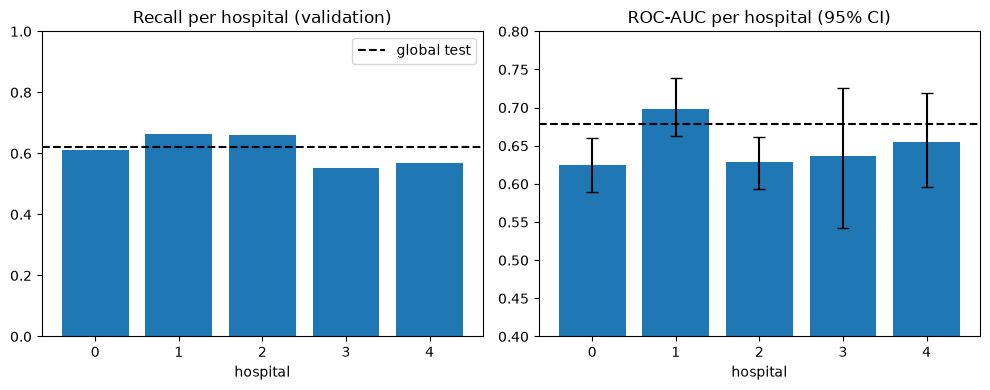

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x = per.index

ax[0].bar(x, per["recall"])
ax[0].axhline(g["recall"], ls="--", c="k", label="global test")
ax[0].set(title="Recall per hospital (validation)", xlabel="hospital", ylim=(0, 1))
ax[0].legend()

err = [per["roc_auc"] - per["auc_lo"], per["auc_hi"] - per["roc_auc"]]
ax[1].bar(x, per["roc_auc"], yerr=err, capsize=4)
ax[1].axhline(g["roc_auc"], ls="--", c="k")
ax[1].set(title="ROC-AUC per hospital (95% CI)", xlabel="hospital", ylim=(0.4, 0.8))

plt.tight_layout()
plt.savefig(FIG / "centralized_per_site.png", dpi=150)
plt.show()

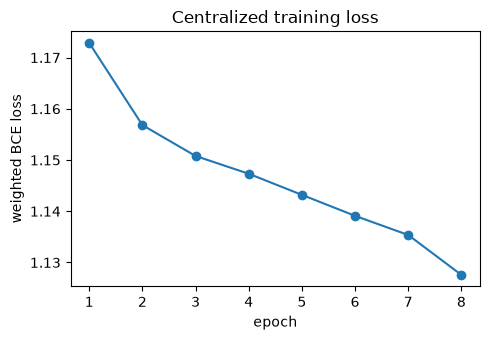

In [6]:
plt.figure(figsize=(5, 3.5))
plt.plot(range(1, len(res["loss_history"]) + 1), res["loss_history"], marker="o")
plt.title("Centralized training loss"); plt.xlabel("epoch"); plt.ylabel("weighted BCE loss")
plt.tight_layout()
plt.savefig(FIG / "centralized_loss.png", dpi=150)
plt.show()

In [7]:
pd.DataFrame({"gap (max - min)": res["fairness_gaps"]}).round(3)

,gap (max - min)
accuracy,0.120
precision,0.249
recall,0.111
f1,0.306
roc_auc,0.074


In [8]:
print("recall range:", per["recall"].min().round(3), "to", per["recall"].max().round(3))
print("ROC-AUC range:", per["roc_auc"].min().round(3), "to", per["roc_auc"].max().round(3))
print("all five AUC intervals share a common region:", per["auc_lo"].max() < per["auc_hi"].min())

recall range: 0.554 to 0.665
ROC-AUC range: 0.625 to 0.698
all five AUC intervals share a common region: False


In [9]:
low  = per["auc_hi"].idxmin()   # hospital with the lowest upper bound
high = per["auc_lo"].idxmax()   # hospital with the highest lower bound
print("lowest:", low, per.loc[low, ["roc_auc", "auc_lo", "auc_hi"]].round(3).tolist())
print("highest:", high, per.loc[high, ["roc_auc", "auc_lo", "auc_hi"]].round(3).tolist())
print("separated:", per.loc[high, "auc_lo"] > per.loc[low, "auc_hi"])

lowest: 0 [0.625, 0.589, 0.661]
highest: 1 [0.698, 0.663, 0.738]
separated: True


### Reading the results

- ROC-AUC of 0.68 on the global test set is in the usual range for 30-day readmission on
  this dataset. The model is informative but far from a strong classifier, and precision is
  low (0.18) because only ~11% of cases are positive.
- Per-site ROC-AUC ranges from 0.625 (hospital 0) to 0.698 (hospital 1), and per-site recall
  from 0.554 to 0.665 (validation sets). Hospital 1's 95% bootstrap interval (0.663 to 0.738)
  does not overlap with those of hospital 0 (0.589 to 0.661) or hospital 2 (0.593 to 0.661),
  but each gap between intervals is only 0.002, so this is borderline evidence that hospital 1
  is served better, not a clear one. All other pairs overlap. The overall gap is modest
  (0.074 in ROC-AUC).
- Recall differences cannot be judged the same way, because no intervals were computed for
  recall. The smaller sites have only 56 to 97 positive validation cases, so a recall
  estimate there has a standard error of roughly 0.05 to 0.07, about half the observed range.
- Precision and F1 differ strongly by hospital (gaps of 0.25 and 0.31) mainly because base
  rates differ (4.8% to 24.8% positive), so we use ROC-AUC and recall as the main fairness
  metrics.
- Hospital 3's validation set has only 56 positives, hence its wide interval.
- Training loss keeps falling, but ROC-AUC on held-out data peaks early and then declines
  (overfitting). The epoch count (8) was chosen on the pooled validation sets, not the test
  set (see `03_epoch_selection.ipynb`). Validation ROC-AUC by epochs: 3 → 0.666, 5 → 0.670,
  8 → 0.672, 10 → 0.665, 15 → 0.659, 20 → 0.649, 30 → 0.635.